# 03 — Conditions de travail
Étudier les associations avec les départs. Les réponses peuvent refléter des situations antérieures ou contemporaines aux départs ; la chronologie est inconnue.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "data.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data.py").exists():
    raise RuntimeError("Lancer depuis la racine du projet ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data import load_data, export_table, attrition_table
from src.plots import plot_attrition, save_figure
df = load_data()


## Heures supplémentaires et déplacements
`OverTime` indique une catégorie déclarée, sans volume d’heures. `BusinessTravel` décrit une fréquence catégorielle, sans nombre de jours.

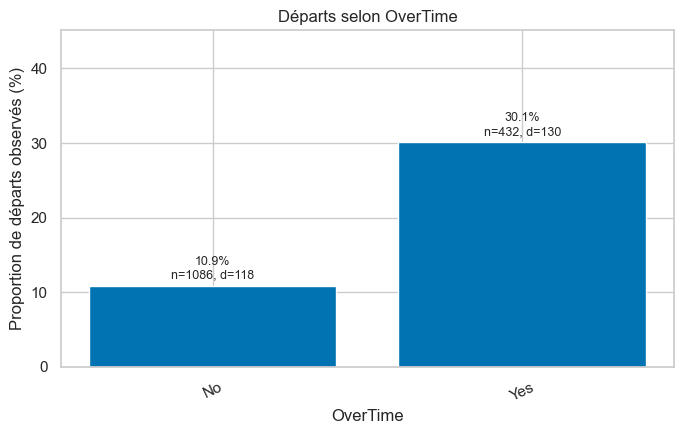

,OverTime,effectif,departs,proportion_depart
0,No,1086,118,0.108656
1,Yes,432,130,0.300926


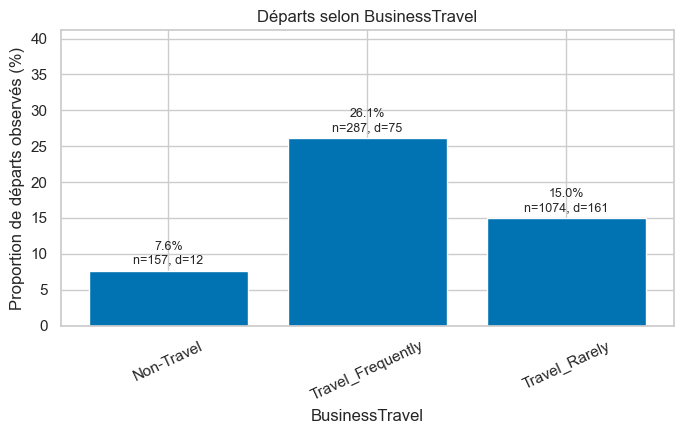

,BusinessTravel,effectif,departs,proportion_depart
0,Non-Travel,157,12,0.076433
1,Travel_Frequently,287,75,0.261324
2,Travel_Rarely,1074,161,0.149907


In [2]:
for col in ["OverTime", "BusinessTravel"]:
    display(export_table(plot_attrition(df, col, f"03_{col}"), f"03_{col}"))

## Distance domicile-travail
Les intervalles sont descriptifs, fixés avant la comparaison. L’unité n’est pas confirmée ; la distance ne donne ni durée ni mode de transport.

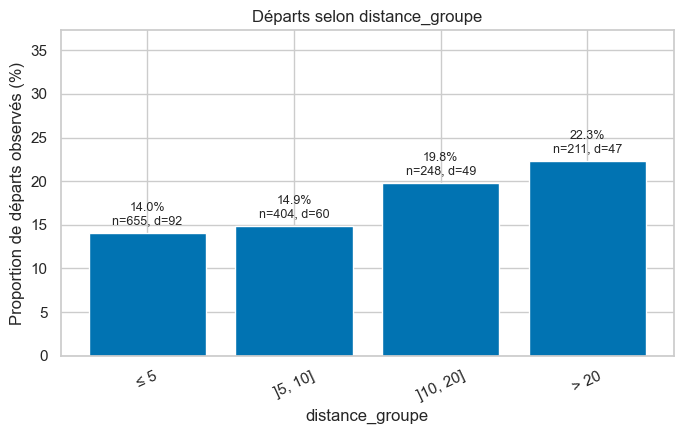

,distance_groupe,effectif,departs,proportion_depart
0,≤ 5,655,92,0.140458
1,"]5, 10]",404,60,0.148515
2,"]10, 20]",248,49,0.197581
3,> 20,211,47,0.222749


,count,mean,median
Attrition,,,
No,1270,8.923622,7.0
Yes,248,10.580645,9.0


In [3]:
df["distance_groupe"] = pd.cut(df.DistanceFromHome, bins=[-np.inf, 5, 10, 20, np.inf], labels=["≤ 5", "]5, 10]", "]10, 20]", "> 20"])
display(export_table(plot_attrition(df, "distance_groupe", "03_distance"), "03_distance"))
display(export_table(df.groupby("Attrition").DistanceFromHome.agg(["count", "mean", "median"]), "03_distance_resume", index=True))

## Équilibre de vie et satisfaction
Afficher toutes les modalités réellement présentes. Le sens et les bornes des échelles restent à confirmer ; aucun regroupement « faible/fort » n’est imposé.

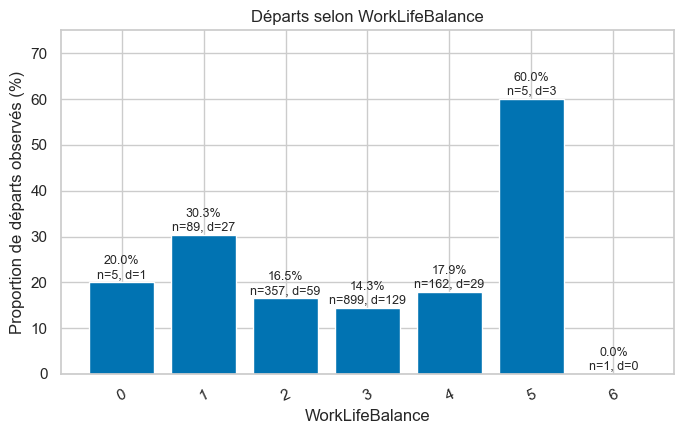

,WorkLifeBalance,effectif,departs,proportion_depart
0,0,5,1,0.200000
1,1,89,27,0.303371
2,2,357,59,0.165266
3,3,899,129,0.143493
4,4,162,29,0.179012
5,5,5,3,0.600000
6,6,1,0,0.000000


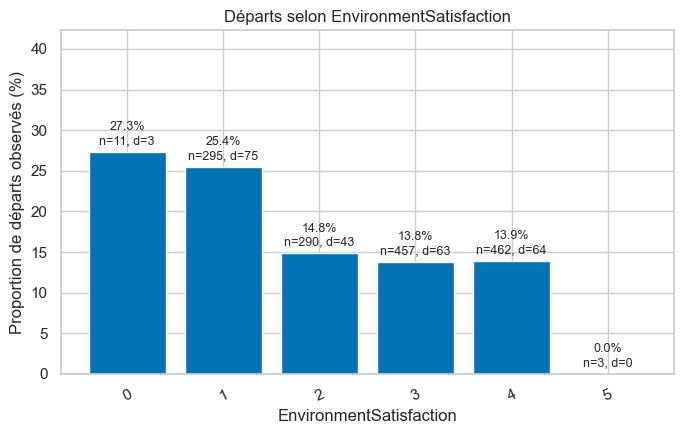

,EnvironmentSatisfaction,effectif,departs,proportion_depart
0,0,11,3,0.272727
1,1,295,75,0.254237
2,2,290,43,0.148276
3,3,457,63,0.137856
4,4,462,64,0.138528
5,5,3,0,0.000000


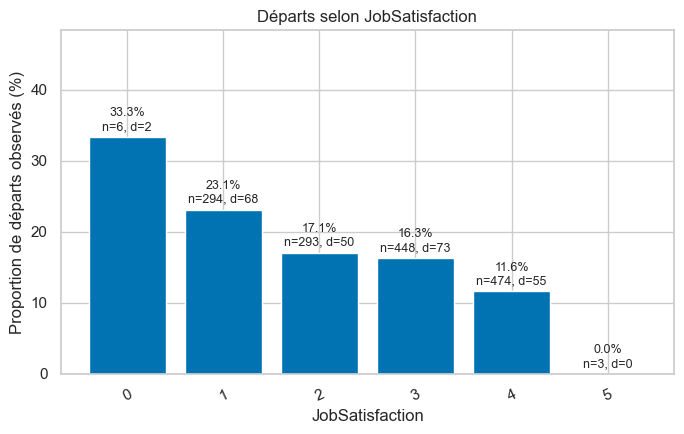

,JobSatisfaction,effectif,departs,proportion_depart
0,0,6,2,0.333333
1,1,294,68,0.231293
2,2,293,50,0.170648
3,3,448,73,0.162946
4,4,474,55,0.116034
5,5,3,0,0.000000


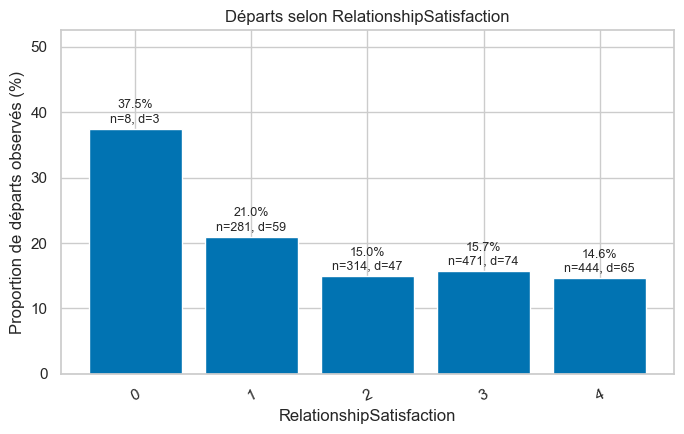

,RelationshipSatisfaction,effectif,departs,proportion_depart
0,0,8,3,0.375000
1,1,281,59,0.209964
2,2,314,47,0.149682
3,3,471,74,0.157113
4,4,444,65,0.146396


In [4]:
scores = ["WorkLifeBalance"] + [c for c in df if "Satisfaction" in c]
for col in scores:
    display(export_table(plot_attrition(df, col, f"03_{col}"), f"03_{col}"))

## Heures supplémentaires à niveau et genre similaires
Cette stratification permet de repérer des différences de composition et des cellules peu fournies. Elle ne constitue pas une preuve causale.

In [5]:
display(export_table(attrition_table(df, ["Gender", "JobLevel", "OverTime"]), "03_overtime_strates"))

,Gender,JobLevel,OverTime,effectif,departs,proportion_depart
0,Female,0,No,2,1,0.500000
1,Female,1,No,142,22,0.154930
2,Female,1,Yes,60,32,0.533333
3,Female,2,No,153,9,0.058824
4,Female,2,Yes,71,9,0.126761
5,Female,3,No,67,8,0.119403
6,Female,3,Yes,29,4,0.137931
7,Female,4,No,34,0,0.000000
8,Female,4,Yes,20,1,0.050000
9,Female,5,No,20,2,0.100000


## Actions à expérimenter et suivi
Examiner la charge et les plannings des équipes faisant des heures supplémentaires ; tester des règles de déplacement, de flexibilité et de récupération adaptées aux métiers et pays. Suivre les volumes d’heures, jours de déplacement, temps de trajet et mesures répétées d’équilibre de vie. Définir une période et des groupes comparables avant d’évaluer les pilotes. L’absentéisme nécessiterait une collecte spécifique, absente du fichier.